# 003 — Trend following as filter design

Every classic trend rule is the sign of a **linear filter of past returns** (Levine &
Pedersen, 2016). With x the log price and r its daily increments:

| rule | signal | kernel on past returns w[k] |
|---|---|---|
| n-day momentum | $x_t - x_{t-n}$ | box: 1 for k < n |
| price above SMA(n) | $x_t - \frac1n\sum_{j<n} x_{t-j}$ | triangle: (n−1−k)/n |
| price above EMA(span n) | $x_t - \mathrm{EMA}_n(x)_t$ | exponential: (1−α)^(k+1), α = 2/(n+1) |

(identities verified numerically in `tests/test_trend.py`). So choosing a trend rule means
choosing an FIR/IIR kernel, and the right comparison is the signal-processing one: **lag**
(centre of mass), **noise gain** and **frequency response**.

In `configs/multi_asset_trend.yaml` the 10-month SMA rule beat 12-month momentum by a Sharpe
ratio of about 0.17. But the two kernels do not have the same lag:

**Hypotheses**

- **H1** At equal lag, the kernel shape (box, triangle, exponential) matters little; the
  lag is what differs between the rules of the experiment.
- **H2** Trend signals have almost no *linear* predictive power for next month's return
  (notebook 001: returns are nearly white); their value comes from the sign nonlinearity:
  cutting exposure during long, persistent declines. In payoff terms, a convex profile.

**Data**: 8 asset-class ETFs (US, developed and emerging equities, long and medium
Treasuries, gold, commodities, real estate) in EUR, 2007-03 → today, the settings of
`configs/multi_asset_trend.yaml`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

from fin.backtest import run_backtest
from fin.backtest.compare import active_returns
from fin.backtest.runner import backtest_config, load_config
from fin.data import load_market_data
from fin.plotting import SERIES, use_style
from fin.signals.trend import (
    apply_kernel,
    ema_kernel,
    frequency_response,
    lag,
    momentum_kernel,
    noise_gain,
    price_minus_smoother,
    sma_kernel,
)
from fin.stats import compare_returns, expected_max_sharpe, probabilistic_sharpe_ratio
from fin.strategy import discover

use_style()
pd.set_option("display.float_format", "{:.3f}".format)

cfg_yaml = load_config("../configs/multi_asset_trend.yaml")
ASSETS = cfg_yaml["strategies"][0]["params"]["tickers"]
cfg = backtest_config(cfg_yaml)
md = load_market_data(ASSETS, currency="EUR")
Trend = discover()["trend_following"]
D = 21  # trading days per month

## 1. The kernels

Return kernels of the three rules of the experiment, normalized to unit sum so they can be
compared as weighting schemes over past returns.

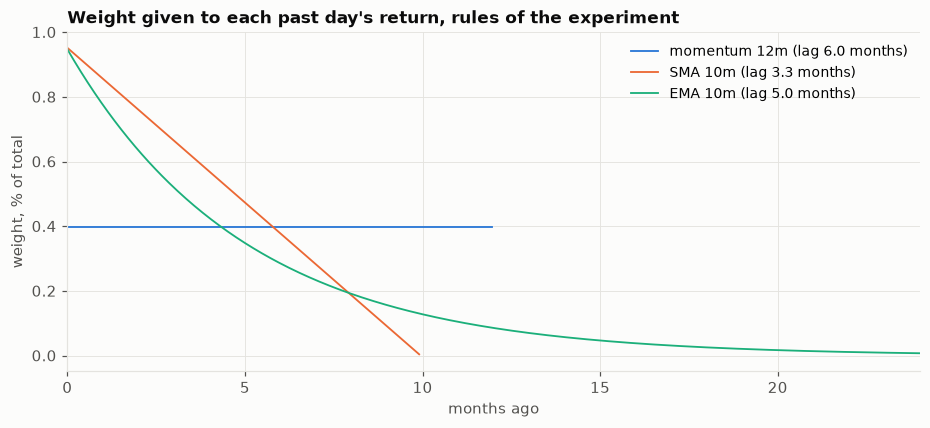

,lag (days),lag (months),noise gain
momentum 12m,125.500,5.976,0.004
SMA 10m,69.333,3.302,0.006
EMA 10m,104.500,4.976,0.005


In [2]:
def return_kernel(rule: str, months: float) -> np.ndarray:
    n = int(round(D * months))
    if rule == "momentum":
        return momentum_kernel(n)
    if rule == "sma":
        return price_minus_smoother(sma_kernel(n))
    return price_minus_smoother(ema_kernel(n, length=12 * n))


experiment_rules = {
    "momentum 12m": return_kernel("momentum", 12),
    "SMA 10m": return_kernel("sma", 10),
    "EMA 10m": return_kernel("ema", 10),
}
fig, ax = plt.subplots()
for (name, w), color in zip(experiment_rules.items(), SERIES, strict=False):
    w = w / w.sum()
    ax.plot(
        np.arange(len(w)) / D, w * 100, color=color, label=f"{name} (lag {lag(w) / D:.1f} months)"
    )
ax.set_xlim(0, 24)
ax.set_title("Weight given to each past day's return, rules of the experiment")
ax.set_xlabel("months ago")
ax.set_ylabel("weight, % of total")
ax.legend()
plt.show()

pd.DataFrame(
    {
        name: {"lag (days)": lag(w), "lag (months)": lag(w) / D, "noise gain": noise_gain(w)}
        for name, w in experiment_rules.items()
    }
).T

The 10-month SMA rule reacts after about 3 months on average; 12-month momentum after 6.
The experiment compared a fast filter with a slow one, so the first question is whether
**lag** explains the gap.

## 2. Equal lag: does the shape matter? (H1)

Lookbacks giving the same lag L: momentum over 2L, SMA over 3L, EMA with span 2L
(centre of mass of a box of length n is (n−1)/2, of the triangle (n−2)/3, of the exponential
(span−1)/2).

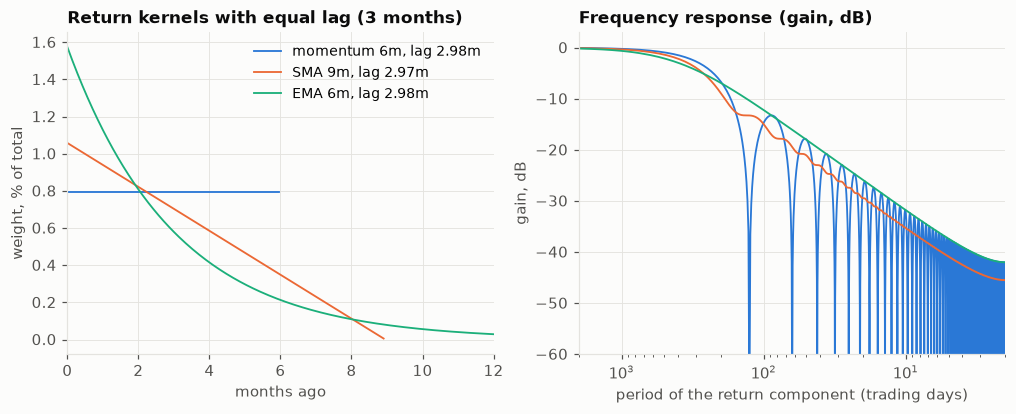

,lag (days),noise gain
momentum 6m,62.500,0.008
SMA 9m,62.333,0.007
EMA 6m,62.500,0.008


In [3]:
lag_months = 3
equal_lag = {
    f"momentum {2 * lag_months}m": return_kernel("momentum", 2 * lag_months),
    f"SMA {3 * lag_months}m": return_kernel("sma", 3 * lag_months),
    f"EMA {2 * lag_months}m": return_kernel("ema", 2 * lag_months),
}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for (name, w), color in zip(equal_lag.items(), SERIES, strict=False):
    w = w / w.sum()
    axes[0].plot(
        np.arange(len(w)) / D, w * 100, color=color, label=f"{name}, lag {lag(w) / D:.2f}m"
    )
    freq, h = frequency_response(w, 4096)
    period = np.divide(1.0, freq, out=np.full_like(freq, np.inf), where=freq > 0)
    axes[1].semilogx(period, 20 * np.log10(np.abs(h) + 1e-12), color=color, label=name)
axes[0].set_xlim(0, 12)
axes[0].set_title(f"Return kernels with equal lag ({lag_months} months)")
axes[0].set_xlabel("months ago")
axes[0].set_ylabel("weight, % of total")
axes[0].legend()
axes[1].set_xlim(2, 2000)
axes[1].set_ylim(-60, 3)
axes[1].invert_xaxis()
axes[1].set_title("Frequency response (gain, dB)")
axes[1].set_xlabel("period of the return component (trading days)")
axes[1].set_ylabel("gain, dB")
plt.show()

pd.DataFrame(
    {name: {"lag (days)": lag(w), "noise gain": noise_gain(w)} for name, w in equal_lag.items()}
).T

Same delay, different shapes. The box (momentum) has the lowest noise gain but sinc
side-lobes: return components with periods near n/1.5 days pass with inverted sign, a
source of whipsaw. The triangle (SMA) is a sinc², with much lower side-lobes. The
exponential has none, but the most noise gain.

Backtest all three kernels at lags of 1 to 4 months, risk-parity weights, same settings as
the experiment. All 12 runs are trials: the deflated hurdle uses them all.

In [4]:
lookbacks = {"momentum": lambda L: 2 * L, "sma": lambda L: 3 * L, "ema": lambda L: 2 * L}
bench = run_backtest(
    Trend(tickers=ASSETS, weighting="equal", always_invested=True), md, cfg, label="equal_weight"
)
r_bench = active_returns(bench)
rf = bench.cash_rate

rows, returns = [], {}
for L in range(1, 5):
    for rule, lb in lookbacks.items():
        res = run_backtest(
            Trend(tickers=ASSETS, lookback_months=lb(L), signal=rule, weighting="inverse_vol"),
            md,
            cfg,
        )
        r = active_returns(res)
        m = res.metrics()
        returns[(rule, L)] = r
        rows.append(
            {
                "lag (months)": L,
                "rule": rule,
                "lookback (months)": lb(L),
                "sharpe": m["sharpe"],
                "max_drawdown": m["max_drawdown"],
                "cagr": m["cagr"],
                "orders": m["n_trades"],
            }
        )
sweep = pd.DataFrame(rows)
bench_m = bench.metrics()
sweep.pivot(index="lag (months)", columns="rule", values="sharpe")

rule,ema,momentum,sma
lag (months),,,
1,0.432,0.567,0.571
2,0.553,0.573,0.592
3,0.571,0.517,0.611
4,0.579,0.547,0.566


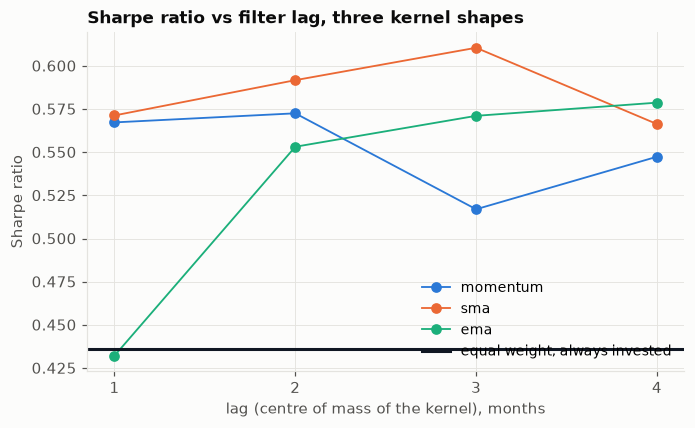

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
for rule, color in zip(lookbacks, SERIES, strict=False):
    s = sweep[sweep["rule"] == rule]
    ax.plot(s["lag (months)"], s["sharpe"], marker="o", color=color, label=rule)
ax.axhline(bench_m["sharpe"], color="#101723", lw=2, label="equal weight, always invested")
ax.set_title("Sharpe ratio vs filter lag, three kernel shapes")
ax.set_xlabel("lag (centre of mass of the kernel), months")
ax.set_ylabel("Sharpe ratio")
ax.set_xticks(range(1, 5))
ax.legend()
plt.show()

Spread between kernel shapes at each lag vs spread between lags for each shape:

In [6]:
pivot = sweep.pivot(index="lag (months)", columns="rule", values="sharpe")
pd.Series(
    {
        "mean Sharpe range across shapes (at fixed lag)": (
            pivot.max(axis=1) - pivot.min(axis=1)
        ).mean(),
        "mean Sharpe range across lags (for fixed shape)": (pivot.max() - pivot.min()).mean(),
    }
)

mean Sharpe range across shapes (at fixed lag)    0.076
mean Sharpe range across lags (for fixed shape)   0.082
dtype: float64

Significance of the best of the 12 trials, deflated for all of them (plus the 6 strategies
of the experiment config, also tried on this data):

In [7]:
best = sweep.loc[sweep["sharpe"].idxmax()]
r_best = returns[(best["rule"], best["lag (months)"])]
t = compare_returns(r_best, r_bench, rf)
n_trials = len(sweep) + 6
trial_std = pd.concat([sweep["sharpe"], pd.Series([0.44, 0.43, 0.44, 0.41, 0.61, 0.60])]).std()
ex = r_best - rf.reindex(r_best.index).fillna(0)
pd.Series(
    {
        "best trial": f"{best['rule']} {best['lookback (months)']}m (lag {best['lag (months)']}m)",
        "Sharpe": best["sharpe"],
        "benchmark Sharpe": bench_m["sharpe"],
        "Sharpe gain, bootstrap p": t["sharpe_diff_p"],
        "worst loss": best["max_drawdown"],
        "benchmark worst loss": bench_m["max_drawdown"],
        "P(true Sharpe > benchmark)": probabilistic_sharpe_ratio(ex, bench_m["sharpe"]),
        f"same, deflated for {n_trials} trials": probabilistic_sharpe_ratio(
            ex, bench_m["sharpe"] + expected_max_sharpe(n_trials, trial_std)
        ),
    },
    dtype=object,
)

best trial                      sma 9m (lag 3m)
Sharpe                                    0.611
benchmark Sharpe                          0.436
Sharpe gain, bootstrap p                  0.065
worst loss                               -0.148
benchmark worst loss                     -0.273
P(true Sharpe > benchmark)                0.779
same, deflated for 18 trials              0.579
dtype: object

## 3. Where does the value come from? (H2)

**Linear predictive power.** For each asset, the correlation between the kernel output at a
month end (lag 3 months, SMA shape) and the next month's return: the information
coefficient (IC).

In [8]:
w = return_kernel("sma", 9)
ics = {}
log_r = np.log(md.adj_close[ASSETS]).diff()
for a in ASSETS:
    r_a = log_r[a].dropna()
    sig = pd.Series(apply_kernel(r_a.to_numpy(), w), index=r_a.index)
    month_end = sig.groupby(sig.index.to_period("M")).tail(1).dropna()
    next_month = r_a.groupby(r_a.index.to_period("M")).sum().shift(-1)
    next_month.index = next_month.index.to_timestamp("M")
    s = pd.Series(month_end.to_numpy(), index=month_end.index.to_period("M").to_timestamp("M"))
    df = pd.concat([s, next_month], axis=1, keys=["signal", "next"], sort=True).dropna()
    ics[a] = {"IC (corr)": df["signal"].corr(df["next"]), "months": len(df)}
ic = pd.DataFrame(ics).T
ic.loc["average"] = ic.mean()
ic

,IC (corr),months
SPY,0.008,266.000
EFA,0.068,266.000
EEM,0.063,266.000
TLT,0.037,266.000
IEF,0.042,266.000
GLD,-0.012,254.000
DBC,0.167,239.000
VNQ,0.036,256.000
average,0.051,259.875


**Convexity.** Quarterly return of the trend portfolio against the quarterly return of the
always-invested portfolio with the same weights. A trend follower cuts exposure in long
declines and keeps it in long rallies, so its payoff curves upward: like holding an option
(Fung & Hsieh, 2001).

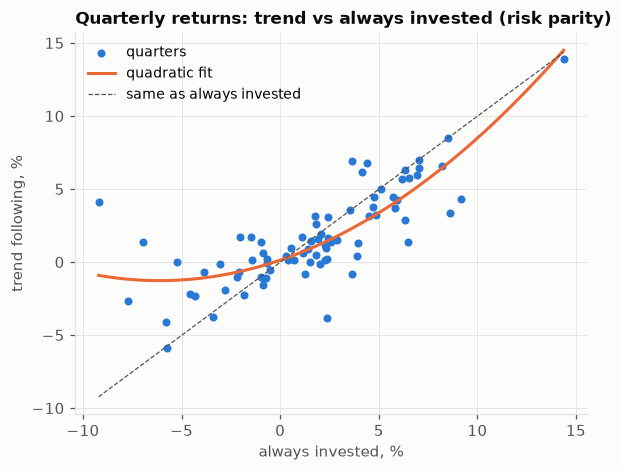

quadratic coefficient (convexity)       3.756
t-stat of convexity (robust)            3.513
avg quarter when market down: always   -0.030
avg quarter when market down: trend    -0.008
avg quarter when market up: always      0.040
avg quarter when market up: trend       0.030
dtype: object

In [9]:
rp = run_backtest(Trend(tickers=ASSETS, weighting="inverse_vol", always_invested=True), md, cfg)
trend_best = run_backtest(
    Trend(
        tickers=ASSETS,
        lookback_months=int(best["lookback (months)"]),
        signal=best["rule"],
        weighting="inverse_vol",
    ),
    md,
    cfg,
)
q = pd.concat(
    [
        (1 + active_returns(rp)).resample("QE").prod() - 1,
        (1 + active_returns(trend_best)).resample("QE").prod() - 1,
    ],
    axis=1,
    keys=["always", "trend"],
).dropna()
coef = np.polyfit(q["always"], q["trend"], 2)
xs = np.linspace(q["always"].min(), q["always"].max(), 100)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(q["always"] * 100, q["trend"] * 100, color=SERIES[0], s=18, label="quarters")
ax.plot(xs * 100, np.polyval(coef, xs) * 100, color=SERIES[1], lw=2, label="quadratic fit")
ax.plot(xs * 100, xs * 100, color="#52514e", lw=0.8, ls="--", label="same as always invested")
ax.set_title("Quarterly returns: trend vs always invested (risk parity)")
ax.set_xlabel("always invested, %")
ax.set_ylabel("trend following, %")
ax.legend()
plt.show()

down = q["always"] < 0
X = sm.add_constant(np.column_stack([q["always"], q["always"] ** 2]))
ols = sm.OLS(q["trend"].to_numpy(), X).fit(cov_type="HC1")
pd.Series(
    {
        "quadratic coefficient (convexity)": ols.params[2],
        "t-stat of convexity (robust)": ols.tvalues[2],
        "avg quarter when market down: always": q.loc[down, "always"].mean(),
        "avg quarter when market down: trend": q.loc[down, "trend"].mean(),
        "avg quarter when market up: always": q.loc[~down, "always"].mean(),
        "avg quarter when market up: trend": q.loc[~down, "trend"].mean(),
    },
    dtype=object,
)

## 4. Conclusions

Numbers from the run on data to 2026-10-23 (8 ETFs in EUR, 2007-03 → today, 5 bps + 1 EUR
per order, orders under 100 EUR skipped).

**The experiment's gap was mostly a lag mismatch.** The 10-month SMA rule has a lag of 3.3
months, 12-month momentum 6.0 months. Comparing them compared a fast filter with a slow one.

**H1 (shape matters little at equal lag): partly supported.**
- At equal lag, the Sharpe spread across kernel shapes (0.08 on average) is as large as the
  spread across lags 1–4 months (0.08). Neither dominates, and both are small against the
  uncertainty: a Sharpe difference of 0.1 is well inside the bootstrap noise for 19 years.
- Frequency domain: at equal lag the box (momentum) has the sharpest cutoff but sinc
  side-lobes around −13 dB, the triangle (SMA) a sinc² with much lower side-lobes, the
  exponential none at all but the highest noise gain. In this sample the triangle came out
  best at 3 of 4 lags; this is suggestive, not established.

**The robust result is at the family level.** 11 of the 12 trend variants beat the
always-invested benchmark's Sharpe (0.44), with Sharpe ratios of 0.52–0.61, and all of them
roughly halved the worst loss. No single variant is significant once the 18 trials are
accounted for (best: SMA 9 months, Sharpe 0.61, bootstrap p = 0.065, deflated probability
0.58). Picking "the best lookback" is noise fitting; picking "a trend filter with a lag of
a few months" is supported.

**H2 (value from nonlinearity, not linear prediction): supported.**
- Linear predictive power is tiny: the average information coefficient of the signal for
  next month's return is 0.05 (R² ≈ 0.25%). It is about zero for US equities (0.01) and
  largest for commodities (0.17), consistent with notebook 001.
- The payoff is clearly convex: the quadratic coefficient of trend vs always-invested
  quarterly returns has a robust t-stat of 3.5. In down quarters the average return goes
  from −3.0% to −0.8%; in up quarters it gives up about 1 point (4.0% → 3.0%).
- Trend following behaves like buying protection, financed by lagging in rallies. That
  explains why it beats on Sharpe and drawdown but not on final wealth.

**What this means for the repo**
- Treat the lookback as a filter design parameter chosen by lag, and stop optimizing it.
- Report trend strategies by drawdown, convexity and Sharpe, not by final value.
- Next steps worth testing: volatility-scaled positions (combine with notebook 001: vol is
  predictable), more assets (diversification across trends is where the literature finds
  the edge), and transaction-cost-aware smoothing of the signal (a band around zero instead
  of a hard sign, to cut whipsaw turnover).